In [154]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sympy as sp

sns.set_theme(context='notebook', style='darkgrid', font='sans-serif')

In [155]:
df = pd.read_csv('../files/titanic_train.csv') # titanic_train -> clean_titanic

In [156]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [157]:
from sklearn.linear_model import LinearRegression

X, y = df[["Fare"]], df['Survived']

lr = LinearRegression().fit(X, y)

result = lr.predict([[0], [200], [512]])

print(result.round(3))

#1.581% omon qoldi degan manoni beryabdi bu notog'ri narsa! shuning uchun logistic regression ishlatamiz (sigmoid)

[0.303 0.807 1.593]


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [158]:
# ======================================= Logistic regreassion =======================================
# Logistic regression = Linear regression + sigmoid

def sigmoid(z): return 1 / (1 + np.exp(-z))

print(f"z=-2  -> {sigmoid(-2):.3f}")
print(f"z=0   -> {sigmoid(0):.3f}")
print(f"z=0.5 -> {sigmoid(0.5):.3f}")
print(f"z=2   -> {sigmoid(2):.3f}")

z=-2  -> 0.119
z=0   -> 0.500
z=0.5 -> 0.622
z=2   -> 0.881


In [159]:
x = sp.symbols('x')
def z(w, b, x): return w * x + b

print(f"w = 2.5, b = -1.4, x = 0 -> {z(2.5, -1.4, 0)}")
print(f"w = 2.5, b = -1.4, x = 1 -> {z(2.5, -1.4, 1)}")

w = 2.5, b = -1.4, x = 0 -> -1.4
w = 2.5, b = -1.4, x = 1 -> 1.1


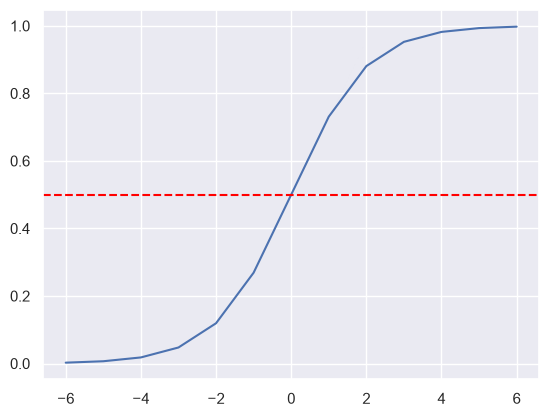

In [160]:
nums = []
for step in np.linspace(-6, 6, 13):
	nums.append(step)

plt.plot(nums, [sigmoid(x) for x in nums])

plt.axhline(y=0.5, color='red', linestyle='--')

plt.show()

In [161]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df.Embarked.fillna("S")

df['Sex'] = df.Sex.map({"male": 0, "female": 1})

df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)

In [162]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,False,False
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,False,True
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,False,True


In [163]:
def feature_engineering(data):
    data = data.copy()

    data["family_size"] = data["SibSp"] + data["Parch"] + 1

    data["is_alone"] = (data["family_size"] == 1).astype(int)

    return data

df = feature_engineering(df)

In [164]:
from sklearn.model_selection import train_test_split

feats = ['Pclass', 'Sex', 'Age', 'Fare', 'family_size', 'is_alone', 'Embarked_Q', 'Embarked_S']

y =  df['Survived']


X_train, X_test, y_train, y_test = train_test_split(
    df[feats], y, test_size=0.2, random_state=42, stratify=y
)

In [165]:
from sklearn.preprocessing import StandardScaler
X_train = X_train.loc[:, ~X_train.columns.duplicated()]
X_test = X_test.loc[:, ~X_test.columns.duplicated()]

sc = StandardScaler().fit(X_train)

X_train_s = sc.transform(X_train)
X_test_s = sc.transform(X_test)

In [166]:
print(f"0 < age <= 15   -> {len(df[(df['Age'] > 0) & (df['Age'] <= 15)])}")
print(f"15 < age <= 30  -> {len(df[(df['Age'] > 15) & (df['Age'] <= 30)])}")
print(f"30 < age <= 45  -> {len(df[(df['Age'] > 30) & (df['Age'] <= 45)])}")
print(f"age > 45        -> {len(df[(df['Age'] > 45)])}")

0 < age <= 15   -> 83
15 < age <= 30  -> 503
30 < age <= 45  -> 202
age > 45        -> 103


In [167]:
from sklearn.linear_model import LogisticRegression

m = LogisticRegression(max_iter=1000)
m.fit(X_train_s, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [176]:
score = m.score(X_test_s, y_test)
print(round(score, 3))

0.793


In [179]:
m.predict(X_test_s)[:5]

array([0, 0, 0, 0, 1])

In [200]:
m.predict_proba(X_test_s)[:5].round(2)

array([[0.92, 0.08],
       [0.95, 0.05],
       [0.88, 0.12],
       [0.96, 0.04],
       [0.42, 0.58]])

In [ ]:
feats = ['Pclass', 'Sex', 'Age', 'family_size']
# 'Fare', , 'is_alone', 'Embarked_Q', 'Embarked_S'

y =  df['Survived']


X_train, X_test, y_train, y_test = train_test_split(
    df[feats], y, test_size=0.2, random_state=42, stratify=y
)

In [189]:
X_train = X_train.loc[:, ~X_train.columns.duplicated()]
X_test = X_test.loc[:, ~X_test.columns.duplicated()]

sc = StandardScaler().fit(X_train)

X_train_s = sc.transform(X_train)
X_test_s = sc.transform(X_test)

In [190]:
m = LogisticRegression(max_iter=1000)
m.fit(X_train_s, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [191]:
score = m.score(X_test_s, y_test)
print(round(score, 2))

0.8


In [199]:
feats = ['Pclass', 'Sex', 'Age', 'family_size']


person = {
	"Pclass": 1,
	'Sex': 1, 
	"Age": 17,
	"family_size": 2
}

person_df = pd.DataFrame([person])[feats]

person_scaled = sc.transform(person_df)

prediction = m.predict(person_scaled)[0]

probabilities = m.predict_proba(person_scaled)[0]

status = "Tirik qolgan (Survived)" if prediction == 1 else "Vafot etgan (Not Survived)"
print(f"Bashorat: {status}")                                   # Bashorat: Tirik qolgan (Survived)
print(f"Tirik qolish ehtimoli: {probabilities[1] * 100:.0f}%") # Tirik qolish ehtimoli: 95.64%

Bashorat: Tirik qolgan (Survived)
Tirik qolish ehtimoli: 96%


In [204]:
print(round(m.score(X_test_s, y_test), 2))

0.8


In [205]:
# FP qimmat'ga tushsa -> Precision'ga etibor bering
# FN qimmat'ga tushsa -> Recall'ga etibor bering

In [206]:
# Precision = TP / (TP + FP)
# Recall = TP / (TP + FN)

CONFUSION MATRIX
[[95 15]
 [20 49]]


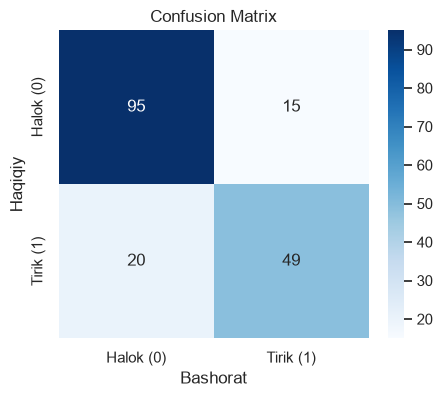


CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Halok (0)       0.83      0.86      0.84       110
   Tirik (1)       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [213]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = m.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred)
print("CONFUSION MATRIX")
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Halok (0)', 'Tirik (1)'], 
            yticklabels=['Halok (0)', 'Tirik (1)'])
plt.ylabel('Haqiqiy')
plt.xlabel('Bashorat')
plt.title('Confusion Matrix')
plt.show()

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, target_names=['Halok (0)', 'Tirik (1)']))

In [211]:
from sklearn.metrics import recall_score, accuracy_score, precision_score

baseline_pred = np.zeros_like(y_test)

base_acc = accuracy_score(y_test, baseline_pred)
base_recall = recall_score(y_test, baseline_pred, zero_division=0)

model_acc = accuracy_score(y_test, y_pred)
model_recall = recall_score(y_test, y_pred)

print(f"TAQQOSLASH (Baseline vs Logistic Regression)")
print(f"Baseline:    Accuracy = {base_acc:.4f} | Recall (tiriklar uchun) = {base_recall:.4f}")
print(f"Bizning model: Accuracy = {model_acc:.4f} | Recall (tiriklar uchun) = {model_recall:.4f}")

TAQQOSLASH (Baseline vs Logistic Regression)
Baseline:    Accuracy = 0.6145 | Recall (tiriklar uchun) = 0.0000
Bizning model: Accuracy = 0.8045 | Recall (tiriklar uchun) = 0.7101


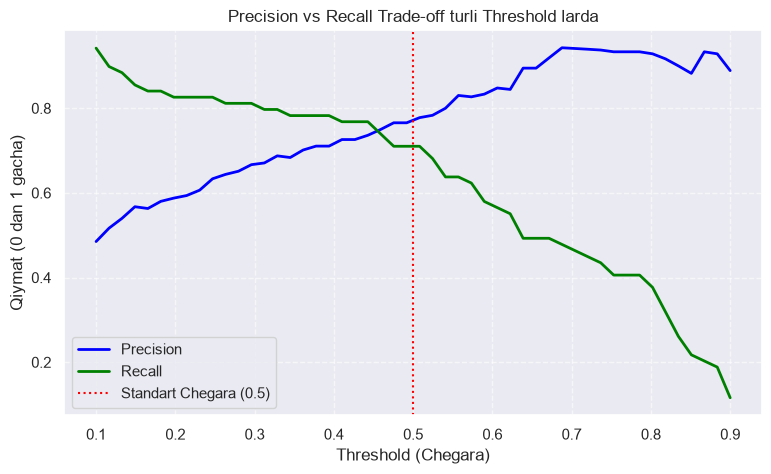

In [212]:
y_probs = m.predict_proba(X_test_s)[:, 1]

thresholds = np.linspace(0.1, 0.9, 50)
precisions = []
recalls = []

for th in thresholds:
    y_pred_th = (y_probs >= th).astype(int)
    
    precisions.append(precision_score(y_test, y_pred_th, zero_division=0))
    recalls.append(recall_score(y_test, y_pred_th, zero_division=0))

plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='green', linewidth=2)

plt.title('Precision vs Recall Trade-off turli Threshold larda')
plt.xlabel('Threshold (Chegara)')
plt.ylabel('Qiymat (0 dan 1 gacha)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axvline(x=0.5, color='red', linestyle=':', label='Standart Chegara (0.5)')
plt.legend()
plt.show()